
# 10 — Model Error Analysis and Feature Importance

## Project: IPL Player Performance Analytics V2

### Objective

Evaluate the selected batting and bowling models using their saved evaluation results, prediction errors, and feature importance.

### Analysis scope

1. Batting Runs Prediction
   - Original Gradient Boosting
   - Square-Root Gradient Boosting

2. Bowling Wickets Prediction
   - Tuned HistGradientBoosting

3. Bowling Runs Conceded Prediction
   - Mean Baseline

4. Bowling Legal Balls Prediction
   - Mean Baseline

5. Bowling Economy Rate Prediction
   - Mean Baseline

### Evaluation methodology

- MAE, RMSE and R²
- Prediction bias and residual analysis
- Actual versus predicted distributions
- Performance across target-value groups
- Feature importance and interpretation
- Final model comparison and limitations

### Important rules

- Preserve chronological train, validation and test separation.
- Do not use test data for model selection.
- Do not retrain models unnecessarily.
- Distinguish measured results from interpretations.
- Load existing model artifacts wherever possible.

### Expected deliverables

- Model evaluation tables
- Error analysis visualizations
- Feature importance reports
- Final model comparison
- Business interpretation and limitations


In [3]:

# ============================================================
# 01 — PROJECT AND MODEL ARTIFACT AUDIT
# ============================================================

from pathlib import Path
import json
import joblib

# Resolve project root from notebook location
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

MODEL_ROOT = PROJECT_ROOT / "models"
DATA_ROOT = PROJECT_ROOT / "data" / "processed"
REPORT_ROOT = PROJECT_ROOT / "artifacts" / "reports"
METRIC_ROOT = PROJECT_ROOT / "artifacts" / "metrics"
FIGURE_ROOT = PROJECT_ROOT / "artifacts" / "figures"

print("=" * 70)
print("IPL MODEL ERROR ANALYSIS — PROJECT AUDIT")
print("=" * 70)

print("\nPROJECT ROOT:", PROJECT_ROOT)
print("MODEL DIRECTORY:", MODEL_ROOT)
print("PROCESSED DATA:", DATA_ROOT)

# Expected saved models
expected_models = {
    "Batting Original GB":
        "batting/original_gb_model.joblib",

    "Batting Square Root GB":
        "batting/sqrt_gb_model.joblib",

    "Bowling Wickets":
        "bowling/wickets_model.joblib",

    "Bowling Runs Conceded":
        "bowling_runs_conceded/baseline_model.joblib",

    "Bowling Legal Balls":
        "bowling_legal_balls/baseline_model.joblib",

    "Bowling Economy Rate":
        "bowling_economy_rate/baseline_model.joblib"
}

print("\n" + "=" * 70)
print("MODEL ARTIFACTS")
print("=" * 70)

for name, relative_path in expected_models.items():

    path = MODEL_ROOT / relative_path

    print(f"\n{name}")
    print("Exists:", path.exists())

    if path.exists():
        print("Size:", round(path.stat().st_size / 1024, 2), "KB")

# Inspect report and metric directories
for name, directory in [
    ("Reports", REPORT_ROOT),
    ("Metrics", METRIC_ROOT),
    ("Figures", FIGURE_ROOT)
]:
    print(f"\n{name} directory:")
    print("Exists:", directory.exists())

    if directory.exists():
        files = sorted(
            p.relative_to(PROJECT_ROOT)
            for p in directory.rglob("*")
            if p.is_file()
        )

        for file in files:
            print(" -", file)

# Inspect available processed CSV files
print("\n" + "=" * 70)
print("PROCESSED DATA FILES")
print("=" * 70)

if DATA_ROOT.exists():
    for path in sorted(DATA_ROOT.rglob("*.csv")):
        print(path.relative_to(PROJECT_ROOT))

print("\nPROJECT AUDIT COMPLETED")


IPL MODEL ERROR ANALYSIS — PROJECT AUDIT

PROJECT ROOT: d:\Git\Personal\ipl-player-performance-v2
MODEL DIRECTORY: d:\Git\Personal\ipl-player-performance-v2\models
PROCESSED DATA: d:\Git\Personal\ipl-player-performance-v2\data\processed

MODEL ARTIFACTS

Batting Original GB
Exists: True
Size: 161.4 KB

Batting Square Root GB
Exists: True
Size: 161.85 KB

Bowling Wickets
Exists: True
Size: 71.87 KB

Bowling Runs Conceded
Exists: True
Size: 1.44 KB

Bowling Legal Balls
Exists: True
Size: 1.44 KB

Bowling Economy Rate
Exists: True
Size: 1.44 KB

Reports directory:
Exists: True

Metrics directory:
Exists: True

Figures directory:
Exists: True

PROCESSED DATA FILES
data\processed\deliveries.csv
data\processed\features\batting_all_model_comparison.csv
data\processed\features\batting_baseline_comparison.csv
data\processed\features\batting_baseline_results.csv
data\processed\features\batting_complete_model_comparison.csv
data\processed\features\batting_model_comparison.csv
data\processed\featu


## 1. Model Performance and Error Analysis

### Objective
Assess the predictive performance, generalization and limitations of the saved IPL batting and bowling models.

### Analysis workflow

1. Inspect existing model comparison results.
2. Load available evaluation metrics and prediction data.
3. Evaluate batting model residuals and prediction errors.
4. Evaluate bowling wickets model residuals and prediction errors.
5. Document baseline performance for the remaining bowling targets.
6. Interpret feature importance where supported by the saved model architecture.
7. Generate final comparison tables, visualizations and reports.

### Evaluation principles

- Use existing validation and test results wherever available.
- Do not retrain models unnecessarily.
- Do not use test data for model selection.
- Distinguish measured feature importance from causal explanations.
- Do not fabricate predictions or evaluation metrics.


In [4]:

# ============================================================
# 02 — EXISTING MODEL RESULTS DISCOVERY
# ============================================================

import pandas as pd
from pathlib import Path

FEATURE_DIR = PROJECT_ROOT / "data" / "processed" / "features"

comparison_files = [
    "batting_all_model_comparison.csv",
    "batting_baseline_comparison.csv",
    "batting_baseline_results.csv",
    "batting_complete_model_comparison.csv",
    "batting_model_comparison.csv"
]

print("=" * 70)
print("EXISTING MODEL COMPARISON RESULTS")
print("=" * 70)

comparison_data = {}

for filename in comparison_files:

    path = FEATURE_DIR / filename

    print(f"\n{'-' * 60}")
    print("FILE:", filename)

    if not path.exists():
        print("NOT FOUND")
        continue

    df = pd.read_csv(path)
    comparison_data[filename] = df

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(5))

# Inspect output directories
print("\n" + "=" * 70)
print("EXISTING REPORT / METRIC / FIGURE FILES")
print("=" * 70)

for folder in [
    REPORT_ROOT,
    METRIC_ROOT,
    FIGURE_ROOT
]:
    files = list(folder.rglob("*"))
    files = [p for p in files if p.is_file()]

    print(f"\n{folder.name}: {len(files)} files")

    for path in files:
        print(" -", path.relative_to(PROJECT_ROOT))

print("\nRESULT DISCOVERY COMPLETED")


EXISTING MODEL COMPARISON RESULTS

------------------------------------------------------------
FILE: batting_all_model_comparison.csv
Shape: (18, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Gradient Boosting 200,15.932161,21.423562,0.117053
1,Gradient Boosting 100,15.953633,21.424681,0.116961
2,Gradient Boosting Depth 3,15.961878,21.419572,0.117382
3,Random Forest Depth 10,16.002567,21.475437,0.112772
4,Ridge Alpha 1000,16.078629,21.447241,0.115101



------------------------------------------------------------
FILE: batting_baseline_comparison.csv
Shape: (6, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Ridge Alpha 100,16.105206,21.452342,0.114680
1,Ridge Alpha 10,16.158372,21.463845,0.113730
2,Ridge Alpha 1,16.188406,21.477762,0.112580
3,Linear Regression,16.193309,21.480407,0.112362
4,Dummy Median,16.683064,24.253256,-0.131595



------------------------------------------------------------
FILE: batting_baseline_results.csv
Shape: (2, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Dummy Mean,17.361069,22.835217,-0.003140
1,Dummy Median,16.683064,24.253256,-0.131595



------------------------------------------------------------
FILE: batting_complete_model_comparison.csv
Shape: (21, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Gradient Boosting 200,15.932161,21.423562,0.117053
1,Gradient Boosting 100,15.953633,21.424681,0.116961
2,Gradient Boosting Depth 3,15.961878,21.419572,0.117382
3,XGBoost 500,15.991414,21.470608,0.113171
4,Random Forest Depth 10,16.002567,21.475437,0.112772



------------------------------------------------------------
FILE: batting_model_comparison.csv
Shape: (15, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Random Forest Depth 10,16.002567,21.475437,0.112772
1,Ridge Alpha 1000,16.078629,21.447241,0.115101
2,Ridge Alpha 3000,16.085646,21.445985,0.115204
3,Ridge Alpha 100,16.105206,21.452342,0.114680
4,Ridge Alpha 10000,16.118473,21.457059,0.114290



EXISTING REPORT / METRIC / FIGURE FILES

reports: 0 files

metrics: 0 files

figures: 0 files

RESULT DISCOVERY COMPLETED


## 2. Saved Model Inspection

Inspect the serialized batting and bowling models to identify:
- Pipeline steps and preprocessing components
- Estimator types
- Available feature-importance attributes
- Input feature metadata

This is a read-only inspection. No model artifacts will be modified.

In [5]:
import joblib
import json
from pathlib import Path

MODEL_DIR = PROJECT_ROOT / "models"

model_paths = {
    "Batting Original GB": MODEL_DIR / "batting" / "original_gb_model.joblib",
    "Batting Square Root GB": MODEL_DIR / "batting" / "sqrt_gb_model.joblib",
    "Bowling Wickets": MODEL_DIR / "bowling" / "wickets_model.joblib",
    "Runs Conceded Baseline": MODEL_DIR / "bowling_runs_conceded" / "baseline_model.joblib",
    "Legal Balls Baseline": MODEL_DIR / "bowling_legal_balls" / "baseline_model.joblib",
    "Economy Rate Baseline": MODEL_DIR / "bowling_economy_rate" / "baseline_model.joblib",
}

for model_name, model_path in model_paths.items():
    print("\n" + "=" * 75)
    print(model_name)
    print("=" * 75)

    model = joblib.load(model_path)

    print("Model type:", type(model).__name__)

    if hasattr(model, "named_steps"):
        print("Pipeline steps:", list(model.named_steps.keys()))

        estimator = model.named_steps.get("model")
        if estimator is not None:
            print("Estimator:", type(estimator).__name__)
            print(
                "Has feature_importances_:",
                hasattr(estimator, "feature_importances_")
            )

    elif hasattr(model, "regressor_"):
        print("Wrapped estimator:", type(model.regressor_).__name__)

        if hasattr(model.regressor_, "named_steps"):
            print("Pipeline steps:", list(model.regressor_.named_steps.keys()))

            estimator = model.regressor_.named_steps.get("model")
            if estimator is not None:
                print("Estimator:", type(estimator).__name__)
                print(
                    "Has feature_importances_:",
                    hasattr(estimator, "feature_importances_")
                )

    elif hasattr(model, "constant_"):
        print("Baseline prediction:", model.constant_)

print("\nMODEL INSPECTION COMPLETED")


Batting Original GB
Model type: Pipeline
Pipeline steps: ['preprocessor', 'model']
Estimator: GradientBoostingRegressor
Has feature_importances_: True

Batting Square Root GB
Model type: TransformedTargetRegressor
Wrapped estimator: Pipeline
Pipeline steps: ['preprocessor', 'model']
Estimator: GradientBoostingRegressor
Has feature_importances_: True

Bowling Wickets
Model type: Pipeline
Pipeline steps: ['preprocessor', 'model']
Estimator: HistGradientBoostingRegressor
Has feature_importances_: False

Runs Conceded Baseline
Model type: DummyRegressor
Baseline prediction: [[26.93704459]]

Legal Balls Baseline
Model type: DummyRegressor
Baseline prediction: [[19.44855727]]

Economy Rate Baseline
Model type: DummyRegressor
Baseline prediction: [[8.62927371]]

MODEL INSPECTION COMPLETED


## 3. Batting Model Feature Importance

Extract feature names from the fitted preprocessing pipelines and
feature importance scores from both saved Gradient Boosting models.

The analysis will:
- Preserve the original model's feature transformations.
- Compare the original-target and square-root-target models.
- Rank features by their contribution to the fitted tree ensembles.

Feature importance indicates model reliance, not causality.

In [6]:
import pandas as pd
import numpy as np
import joblib

# Load the two saved batting models
batting_original = joblib.load(
    MODEL_DIR / "batting" / "original_gb_model.joblib"
)

batting_sqrt = joblib.load(
    MODEL_DIR / "batting" / "sqrt_gb_model.joblib"
)


def extract_gb_feature_importance(model, model_name):
    """
    Extract transformed feature names and Gradient Boosting
    feature importance from a fitted pipeline.
    """

    # Handle TransformedTargetRegressor
    if hasattr(model, "regressor_"):
        pipeline = model.regressor_
    else:
        pipeline = model

    preprocessor = pipeline.named_steps["preprocessor"]
    estimator = pipeline.named_steps["model"]

    feature_names = preprocessor.get_feature_names_out()
    importances = estimator.feature_importances_

    if len(feature_names) != len(importances):
        raise ValueError(
            f"Feature mismatch in {model_name}: "
            f"{len(feature_names)} names vs "
            f"{len(importances)} importance scores"
        )

    result = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    result = result.sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    result["Rank"] = np.arange(1, len(result) + 1)
    result["Model"] = model_name

    return result[
        ["Model", "Rank", "Feature", "Importance"]
    ]


# Extract importance from both models
original_importance = extract_gb_feature_importance(
    batting_original,
    "Original GB"
)

sqrt_importance = extract_gb_feature_importance(
    batting_sqrt,
    "Square Root GB"
)

# Display top 20 features
print("ORIGINAL GRADIENT BOOSTING — TOP 20 FEATURES")
display(original_importance.head(20))

print("\nSQUARE ROOT GRADIENT BOOSTING — TOP 20 FEATURES")
display(sqrt_importance.head(20))

print("\nFEATURE IMPORTANCE SUMMARY")
print("Original GB features:", len(original_importance))
print("Square Root GB features:", len(sqrt_importance))

ORIGINAL GRADIENT BOOSTING — TOP 20 FEATURES


,Model,Rank,Feature,Importance
0,Original GB,1,numerical__runs_scored_expanding_mean,0.176805
1,Original GB,2,numerical__fours_expanding_mean,0.162043
2,Original GB,3,numerical__balls_faced_rolling_mean_10,0.155017
3,Original GB,4,numerical__balls_faced_expanding_mean,0.127412
4,Original GB,5,numerical__balls_faced_rolling_mean_3,0.043578
5,Original GB,6,numerical__runs_scored_rolling_mean_10,0.042603
6,Original GB,7,numerical__matches_played_before,0.040800
7,Original GB,8,numerical__dismissals_expanding_mean,0.029656
8,Original GB,9,numerical__balls_faced,0.025976
9,Original GB,10,numerical__fours_rolling_mean_5,0.022474



SQUARE ROOT GRADIENT BOOSTING — TOP 20 FEATURES


,Model,Rank,Feature,Importance
0,Square Root GB,1,numerical__balls_faced_rolling_mean_10,0.222958
1,Square Root GB,2,numerical__runs_scored_expanding_mean,0.170513
2,Square Root GB,3,numerical__balls_faced_expanding_mean,0.147496
3,Square Root GB,4,numerical__fours_expanding_mean,0.082275
4,Square Root GB,5,numerical__runs_scored_rolling_mean_10,0.059783
5,Square Root GB,6,numerical__matches_played_before,0.055395
6,Square Root GB,7,numerical__balls_faced_rolling_mean_3,0.034613
7,Square Root GB,8,numerical__balls_faced,0.030666
8,Square Root GB,9,numerical__dismissals_expanding_mean,0.027407
9,Square Root GB,10,numerical__balls_faced_rolling_mean_5,0.018112



FEATURE IMPORTANCE SUMMARY
Original GB features: 74
Square Root GB features: 72


In [7]:
# Compare feature importance across both batting models

original = original_importance[
    ["Feature", "Importance"]
].rename(columns={
    "Importance": "Original_GB_Importance"
})

sqrt = sqrt_importance[
    ["Feature", "Importance"]
].rename(columns={
    "Importance": "Sqrt_GB_Importance"
})

importance_comparison = original.merge(
    sqrt,
    on="Feature",
    how="outer"
).fillna(0)

importance_comparison["Original_Rank"] = (
    importance_comparison["Original_GB_Importance"]
    .rank(method="min", ascending=False)
    .astype(int)
)

importance_comparison["Sqrt_Rank"] = (
    importance_comparison["Sqrt_GB_Importance"]
    .rank(method="min", ascending=False)
    .astype(int)
)

importance_comparison["Rank_Difference"] = (
    importance_comparison["Original_Rank"]
    - importance_comparison["Sqrt_Rank"]
)

importance_comparison["Average_Importance"] = (
    importance_comparison[
        ["Original_GB_Importance", "Sqrt_GB_Importance"]
    ].mean(axis=1)
)

importance_comparison = importance_comparison.sort_values(
    "Average_Importance",
    ascending=False
).reset_index(drop=True)

print("FEATURE IMPORTANCE COMPARISON")
display(importance_comparison.head(20))

common_features = set(original["Feature"]) & set(sqrt["Feature"])
original_only = set(original["Feature"]) - common_features
sqrt_only = set(sqrt["Feature"]) - common_features

print("\nFEATURE OVERLAP")
print("Common features:", len(common_features))
print("Original GB only:", len(original_only))
print("Square Root GB only:", len(sqrt_only))

print("\nORIGINAL GB ONLY")
print(sorted(original_only))

print("\nSQUARE ROOT GB ONLY")
print(sorted(sqrt_only))

FEATURE IMPORTANCE COMPARISON


,Feature,Original_GB_Importance,Sqrt_GB_Importance,Original_Rank,Sqrt_Rank,Rank_Difference,Average_Importance
0,numerical__balls_faced_rolling_mean_10,0.155017,0.222958,3,1,2,0.188987
1,numerical__runs_scored_expanding_mean,0.176805,0.170513,1,2,-1,0.173659
2,numerical__balls_faced_expanding_mean,0.127412,0.147496,4,3,1,0.137454
3,numerical__fours_expanding_mean,0.162043,0.082275,2,4,-2,0.122159
4,numerical__runs_scored_rolling_mean_10,0.042603,0.059783,6,5,1,0.051193
5,numerical__matches_played_before,0.040800,0.055395,7,6,1,0.048098
6,numerical__balls_faced_rolling_mean_3,0.043578,0.034613,5,7,-2,0.039096
7,numerical__dismissals_expanding_mean,0.029656,0.027407,8,9,-1,0.028531
8,numerical__balls_faced,0.025976,0.030666,9,8,1,0.028321
9,numerical__fours_rolling_mean_5,0.022474,0.014406,10,12,-2,0.018440



FEATURE OVERLAP
Common features: 72
Original GB only: 2
Square Root GB only: 0

ORIGINAL GB ONLY
['numerical__batting_average', 'numerical__not_out_innings']

SQUARE ROOT GB ONLY
[]


In [8]:
from scipy.stats import spearmanr

# Compare only features shared by both models
common_comparison = importance_comparison[
    importance_comparison["Original_GB_Importance"].gt(0)
    & importance_comparison["Sqrt_GB_Importance"].gt(0)
].copy()

# Rank correlation
spearman_corr, spearman_p = spearmanr(
    common_comparison["Original_Rank"],
    common_comparison["Sqrt_Rank"]
)

# Top-10 overlap
original_top10 = set(
    original_importance.head(10)["Feature"]
)

sqrt_top10 = set(
    sqrt_importance.head(10)["Feature"]
)

top10_common = original_top10 & sqrt_top10
top10_union = original_top10 | sqrt_top10

jaccard_top10 = len(top10_common) / len(top10_union)

print("RANKING STABILITY")
print(f"Common features: {len(common_comparison)}")
print(f"Spearman correlation: {spearman_corr:.4f}")
print(f"Spearman p-value: {spearman_p:.6f}")

print("\nTOP-10 OVERLAP")
print(f"Shared top-10 features: {len(top10_common)}")
print(f"Jaccard similarity: {jaccard_top10:.4f}")

print("\nFEATURES SHARED IN TOP 10")
for feature in sorted(top10_common):
    print("-", feature)

RANKING STABILITY
Common features: 40
Spearman correlation: 0.8737
Spearman p-value: 0.000000

TOP-10 OVERLAP
Shared top-10 features: 9
Jaccard similarity: 0.8182

FEATURES SHARED IN TOP 10
- numerical__balls_faced
- numerical__balls_faced_expanding_mean
- numerical__balls_faced_rolling_mean_10
- numerical__balls_faced_rolling_mean_3
- numerical__dismissals_expanding_mean
- numerical__fours_expanding_mean
- numerical__matches_played_before
- numerical__runs_scored_expanding_mean
- numerical__runs_scored_rolling_mean_10


## 4. Bowling Wickets — Permutation Feature Importance

HistGradientBoostingRegressor does not expose built-in impurity-based
feature importance.

Permutation importance measures the reduction in model performance
when an individual feature is randomly shuffled.

We will use held-out data and the negative MAE scoring metric.
A larger importance indicates greater reliance on that feature
for predictive performance on the evaluation dataset.

In [9]:
import json
import pandas as pd
from pathlib import Path

# Locate saved metadata and metrics
wickets_metadata_path = (
    MODEL_DIR / "bowling" / "wickets_feature_metadata.json"
)

wickets_metrics_path = (
    MODEL_DIR / "bowling" / "wickets_model_metrics.json"
)

bowling_dataset_path = (
    PROJECT_ROOT / "data" / "processed" /
    "features" / "bowling_model_dataset.csv"
)

# Read metadata
with open(wickets_metadata_path, "r") as f:
    wickets_metadata = json.load(f)

with open(wickets_metrics_path, "r") as f:
    wickets_metrics = json.load(f)

print("=" * 70)
print("WICKETS FEATURE METADATA")
print("=" * 70)
print(json.dumps(wickets_metadata, indent=4, default=str))

print("\n" + "=" * 70)
print("WICKETS MODEL METRICS")
print("=" * 70)
print(json.dumps(wickets_metrics, indent=4, default=str))

# Inspect the processed bowling dataset
bowling_df = pd.read_csv(bowling_dataset_path)

print("\n" + "=" * 70)
print("BOWLING DATASET")
print("=" * 70)
print("Shape:", bowling_df.shape)
print("Columns:", bowling_df.columns.tolist())

if "date" in bowling_df.columns:
    bowling_df["date"] = pd.to_datetime(
        bowling_df["date"], errors="coerce"
    )
    print("Date range:", bowling_df["date"].min(),
          "to", bowling_df["date"].max())

print("\nTarget distribution:")
target_col = "target_next_match_wickets"

if target_col in bowling_df.columns:
    print(bowling_df[target_col].describe())
else:
    print(f"Target column not found: {target_col}")

WICKETS FEATURE METADATA
{
    "model_name": "Bowling Wickets Prediction",
    "target": "target_next_match_wickets",
    "prediction_definition": "Predicts wickets in the player's next recorded regular appearance, using information available after the current match.",
    "features": [
        "is_super_over",
        "runs_conceded",
        "legal_balls",
        "wides_conceded",
        "noballs_conceded",
        "innings_bowled",
        "wickets",
        "overs_bowled",
        "economy_rate",
        "bowling_average",
        "bowling_strike_rate",
        "season",
        "match_type",
        "days_since_previous_match",
        "previous_wickets",
        "wickets_rolling_mean_3",
        "wickets_rolling_mean_5",
        "wickets_rolling_mean_10",
        "wickets_expanding_mean",
        "previous_runs_conceded",
        "runs_conceded_rolling_mean_3",
        "runs_conceded_rolling_mean_5",
        "runs_conceded_rolling_mean_10",
        "runs_conceded_expanding_mean

In [10]:
# Reconstruct the chronological test dataset
# using the same boundaries established in Notebook 09.

TARGET = "target_next_match_wickets"

FEATURES = wickets_metadata["features"]

train_end = pd.Timestamp("2022-04-11")
validation_end = pd.Timestamp("2024-05-01")

train_mask = bowling_df["date"] <= train_end

validation_mask = (
    (bowling_df["date"] > train_end)
    & (bowling_df["date"] <= validation_end)
)

test_mask = bowling_df["date"] > validation_end

train_df = bowling_df.loc[train_mask].copy()
validation_df = bowling_df.loc[validation_mask].copy()
test_df = bowling_df.loc[test_mask].copy()

# Prepare test features and target
X_test_wickets = test_df[FEATURES].copy()
y_test_wickets = test_df[TARGET].copy()

print("CHRONOLOGICAL SPLIT VERIFICATION")
print("-" * 60)

for name, split in [
    ("Train", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(split):,} rows | "
        f"{split['date'].min().date()} to "
        f"{split['date'].max().date()}"
    )

print("\nTEST DATA VALIDATION")
print("Expected test rows:", wickets_metrics["test_rows"])
print("Actual test rows:", len(X_test_wickets))
print("Expected features:", len(FEATURES))
print("Actual features:", X_test_wickets.shape[1])
print("Missing feature values:", X_test_wickets.isna().sum().sum())
print("Missing target values:", y_test_wickets.isna().sum())

assert len(train_df) == 10293
assert len(validation_df) == 2025
assert len(test_df) == wickets_metrics["test_rows"]
assert list(X_test_wickets.columns) == FEATURES
assert y_test_wickets.notna().all()

print("\nTEST DATA RECONSTRUCTION VERIFIED")

CHRONOLOGICAL SPLIT VERIFICATION
------------------------------------------------------------
Train: 10,293 rows | 2008-04-18 to 2022-04-11
Validation: 2,025 rows | 2022-04-12 to 2024-05-01
Test: 1,805 rows | 2024-05-02 to 2026-05-29

TEST DATA VALIDATION
Expected test rows: 1805
Actual test rows: 1805
Expected features: 35
Actual features: 35
Missing feature values: 2218
Missing target values: 0

TEST DATA RECONSTRUCTION VERIFIED


In [11]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

# Load the saved wickets model
wickets_model = joblib.load(
    MODEL_DIR / "bowling" / "wickets_model.joblib"
)

# Predict using the complete saved pipeline
y_pred_wickets = wickets_model.predict(X_test_wickets)

# Calculate test metrics
test_mae = mean_absolute_error(
    y_test_wickets, y_pred_wickets
)

test_rmse = np.sqrt(
    mean_squared_error(y_test_wickets, y_pred_wickets)
)

test_r2 = r2_score(
    y_test_wickets, y_pred_wickets
)

test_poisson = mean_poisson_deviance(
    y_test_wickets,
    np.maximum(y_pred_wickets, 1e-10)
)

print("RECONSTRUCTED TEST PERFORMANCE")
print("-" * 55)
print(f"MAE:             {test_mae:.6f}")
print(f"RMSE:            {test_rmse:.6f}")
print(f"R2:              {test_r2:.6f}")
print(f"Poisson Deviance: {test_poisson:.6f}")

print("\nSAVED METRICS COMPARISON")
print("-" * 55)

for metric, actual in [
    ("MAE", test_mae),
    ("RMSE", test_rmse),
    ("R2", test_r2),
    ("Poisson Deviance", test_poisson)
]:
    expected = wickets_metrics["test"][metric]
    print(
        f"{metric}: saved={expected:.6f}, "
        f"reconstructed={actual:.6f}, "
        f"match={np.isclose(expected, actual, atol=1e-6)}"
    )

print("\nPREDICTION CHECK")
print("Predictions:", len(y_pred_wickets))
print("Prediction minimum:", y_pred_wickets.min())
print("Prediction maximum:", y_pred_wickets.max())
print("Missing predictions:", np.isnan(y_pred_wickets).sum())

RECONSTRUCTED TEST PERFORMANCE
-------------------------------------------------------
MAE:             0.763657
RMSE:            0.993646
R2:              0.023595
Poisson Deviance: 1.161079

SAVED METRICS COMPARISON
-------------------------------------------------------
MAE: saved=0.763657, reconstructed=0.763657, match=True
RMSE: saved=0.993646, reconstructed=0.993646, match=True
R2: saved=0.023595, reconstructed=0.023595, match=True
Poisson Deviance: saved=1.161079, reconstructed=1.161079, match=True

PREDICTION CHECK
Predictions: 1805
Prediction minimum: 0.48898491679994743
Prediction maximum: 1.1351799282683606
Missing predictions: 0


### 4.1 Permutation Importance — Bowling Wickets

Calculate permutation importance on the reconstructed chronological
test dataset using negative mean absolute error.

A feature is considered important when shuffling its values
increases prediction error.

Use multiple repeats to reduce the effect of random shuffling.

In [12]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on held-out test data
wickets_permutation = permutation_importance(
    estimator=wickets_model,
    X=X_test_wickets,
    y=y_test_wickets,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create feature-importance dataframe
wickets_importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance_Mean": wickets_permutation.importances_mean,
    "Importance_Std": wickets_permutation.importances_std
})

wickets_importance_df = wickets_importance_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

wickets_importance_df["Rank"] = (
    np.arange(1, len(wickets_importance_df) + 1)
)

wickets_importance_df = wickets_importance_df[
    ["Rank", "Feature", "Importance_Mean", "Importance_Std"]
]

print("BOWLING WICKETS — PERMUTATION IMPORTANCE")
display(wickets_importance_df.head(20))

print("\nIMPORTANCE SUMMARY")
print("Total features:", len(wickets_importance_df))
print(
    "Positive importance:",
    (wickets_importance_df["Importance_Mean"] > 0).sum()
)
print(
    "Negative importance:",
    (wickets_importance_df["Importance_Mean"] < 0).sum()
)

BOWLING WICKETS — PERMUTATION IMPORTANCE


,Rank,Feature,Importance_Mean,Importance_Std
0,1,legal_balls_rolling_mean_10,0.008133,0.001804
1,2,runs_conceded_rolling_mean_10,0.003598,0.001141
2,3,legal_balls_rolling_mean_5,0.002713,0.000731
3,4,runs_conceded_expanding_mean,0.002169,0.000638
4,5,legal_balls,0.000649,0.000453
5,6,matches_played_before,0.000438,0.000373
6,7,legal_balls_expanding_mean,0.000326,0.000151
7,8,runs_conceded,0.000215,0.000089
8,9,runs_conceded_rolling_mean_3,0.000165,0.000099
9,10,wickets,0.000049,0.000130



IMPORTANCE SUMMARY
Total features: 35
Positive importance: 13
Negative importance: 10


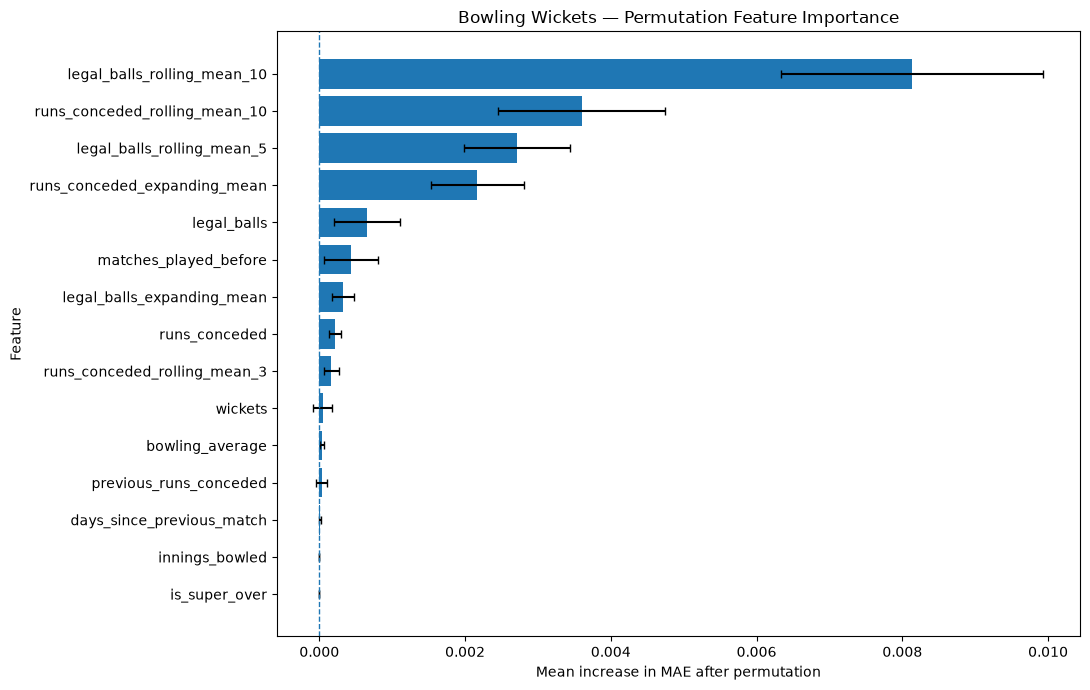

In [13]:
import matplotlib.pyplot as plt

# Top 15 features
top_features = wickets_importance_df.head(15).sort_values(
    "Importance_Mean",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"],
    capsize=3
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("Mean increase in MAE after permutation")
plt.ylabel("Feature")
plt.title("Bowling Wickets — Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [14]:
# Save bowling wickets permutation importance results

import json

METRICS_DIR = PROJECT_ROOT / "metrics"
FIGURES_DIR = PROJECT_ROOT / "figures"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Save importance table
importance_csv_path = (
    METRICS_DIR / "bowling_wickets_permutation_importance.csv"
)

wickets_importance_df.to_csv(
    importance_csv_path,
    index=False
)

# Save chart
importance_figure_path = (
    FIGURES_DIR / "bowling_wickets_permutation_importance.png"
)

plt.gcf().savefig(
    importance_figure_path,
    dpi=300,
    bbox_inches="tight"
)

# Save analysis metadata
importance_summary = {
    "model": "Bowling Wickets Prediction",
    "method": "Permutation Importance",
    "evaluation_dataset": "Chronological Test Set",
    "test_rows": int(len(X_test_wickets)),
    "features_evaluated": int(len(FEATURES)),
    "scoring": "neg_mean_absolute_error",
    "n_repeats": 10,
    "random_state": 42,
    "top_feature": str(
        wickets_importance_df.iloc[0]["Feature"]
    ),
    "top_importance": float(
        wickets_importance_df.iloc[0]["Importance_Mean"]
    )
}

summary_path = METRICS_DIR / "bowling_wickets_importance_summary.json"

with open(summary_path, "w") as f:
    json.dump(importance_summary, f, indent=4)

print("SAVED SUCCESSFULLY")
print(importance_csv_path)
print(importance_figure_path)
print(summary_path)

SAVED SUCCESSFULLY
d:\Git\Personal\ipl-player-performance-v2\metrics\bowling_wickets_permutation_importance.csv
d:\Git\Personal\ipl-player-performance-v2\figures\bowling_wickets_permutation_importance.png
d:\Git\Personal\ipl-player-performance-v2\metrics\bowling_wickets_importance_summary.json


<Figure size 640x480 with 0 Axes>

# 10 — Model Error Analysis and Feature Importance

## Objectives
1. Review saved model performance.
2. Compare batting model feature importance.
3. Evaluate batting feature-ranking stability.
4. Analyze bowling wickets using permutation importance.
5. Document weak baseline results for other bowling targets.
6. Summarize model limitations and recommendations.

## Key Findings

### Batting
- Gradient Boosting models show similar feature-ranking patterns.
- Spearman rank correlation: 0.8737.
- Top-10 Jaccard similarity: 0.8182.
- Historical runs scored, balls faced and fours are important predictors.

### Bowling Wickets
- Test MAE: 0.763657.
- Test RMSE: 0.993646.
- Test R²: 0.023595.
- Test Poisson deviance: 1.161079.
- The model modestly outperforms the mean baseline.
- Legal balls rolling mean over 10 matches has the highest permutation importance.

### Other Bowling Targets
- Mean baselines were retained for runs conceded, legal balls and economy rate.
- More complex models did not demonstrate sufficiently reliable improvements.

## Limitations
- Low predictive explanatory power.
- Feature importance does not establish causality.
- Correlated historical features can distribute importance.
- IPL player performance is influenced by match context and opportunity.
- Historical patterns may not fully represent future player performance.

## Conclusion
The models provide useful analytical baselines, but their predictive reliability varies by target. Further improvements should prioritize feature engineering, contextual variables and robust temporal validation.